Author: Jamal Toutouh (www.jamal.es)

It contains the code to show an example about using Generative Adversarial Networks. In this case, the GAN is used to generate vectors of a given size that contains float numbers that follow a Normal distribution defined my the mean and standard deviation.

In [ ]:
"""
Author: Jamal Toutouh (www.jamal.es)

It contains the code to show an example about using Generative Adversarial Networks. In this case, the
GAN is used to generate vectors of a given size that contains float numbers that follow a Normal distribution
defined my the mean and standard deviation.
"""

import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions.normal import Normal
from torch.autograd import Variable

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm


Código para que se use la GPU si está disponible

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Después hay que usar xxx.to(device)

Definimos los datos reales: distribución normal de media *real_data_mean* y desviación estándar *real_data_stddev*

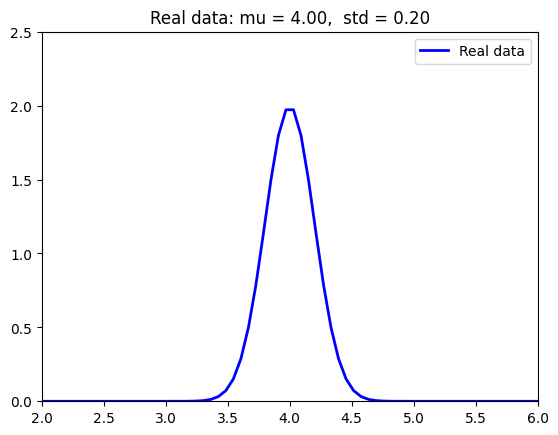

In [ ]:
# Real data set: Samples from a normal distribution given real_data_mean and real_data_sttdev
real_data_mean = 4.0
real_data_stddev = 0.2


def plot_data(real_mean, real_sigma, fake_data=None, epoch=None):
    x = np.linspace(1, 7, 100)
    plt.figure()

    real_data_distribution = norm.pdf(x, real_mean, real_sigma)
    plt.plot(x, real_data_distribution, 'b', linewidth=2, label='Real data')

    if not (fake_data is None):
      mu, std = norm.fit(fake_data.tolist())
      fake_data_distribution = norm.pdf(x, mu, std)
      plt.plot(x, fake_data_distribution, 'r', linewidth=2, label='Fake data')
      title = "Fit results: mu = %.2f,  std = %.2f" % (mu, std)
    else:
      title = "Real data: mu = %.2f,  std = %.2f" % (real_mean, real_sigma)
      epoch = "real"
    plt.xlim(2,6)
    plt.ylim(0, 2.5)
    plt.title(title)
    plt.legend()
    plt.savefig('01-1d-normal-gan-data-{}.png'.format(epoch))
    plt.show()

def get_real_sampler(mu, sigma):
    """
    Creates a lambda function to create samples of the real data (Normal) distribution
    :param mu: Mean of the real data distribution
    :param sigma: Standard deviation of the real data distribution
    :return: Lambda function sampler
    """
    dist = Normal(mu,sigma )
    return lambda m, n: dist.sample((m, n)).requires_grad_()


# Load samples from real data
get_real_data = get_real_sampler(real_data_mean, real_data_stddev)
plot_data(real_data_mean, real_data_stddev)


Función que crea los vectores del espacio latente que leerá el generador para crear los datos

In [ ]:
def read_latent_space(batch_size, latent_vector_size):
    """
    Creates a tensor with random values fro latent space  with shape = size
    :param size: Size of the tensor (batch size).
    :return: Tensor with random values (z) with shape = size
    """
    z = torch.rand(batch_size, latent_vector_size)
    if torch.cuda.is_available(): return z.cuda()
    return z.to(device)


Clase que define el generador

In [ ]:
class Generator(nn.Module):
    """
    Class that defines the the Generator Neural Network
    """
    def __init__(self, input_size, hidden_size, output_size):
        super(Generator, self).__init__()

        self.net = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.SELU(),
            nn.Linear(hidden_size, hidden_size),
            nn.SELU(),
            nn.Linear(hidden_size, output_size),
            nn.SELU(),
        )

    def forward(self, x):
        x = self.net(x.to(device))
        return x

Clase que define el discriminador

In [ ]:
class Discriminator(nn.Module):
    """
    Class that defines the the Discriminator Neural Network
    """
    def __init__(self, input_size, hidden_size, output_size):
        super(Discriminator, self).__init__()

        self.net = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.SELU(),
            nn.Linear(hidden_size, hidden_size),
            nn.SELU(),
            nn.Linear(hidden_size, output_size),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.net(x.to(device))
        return x


Función auxiliar para mostrar la evolución de la función de pérdida del  generador y el discriminador

In [ ]:
def plot_loss_evolution(discriminator_loss, generator_loss):
    x = range(len(discriminator_loss)) if len(discriminator_loss) > 0 else range(len(generator_loss))
    if len(discriminator_loss) > 0: plt.plot(x, discriminator_loss, '-b', label='Discriminator loss')
    if len(generator_loss) > 0: plt.plot(x, generator_loss, ':r', label='Generator loss')
    plt.legend()
    plt.savefig('01-1d-normal-gan-loss.png')
    plt.show()

Funciones para crear las etiquetas de dato real *real_data_target* y dato falso *fake_data_target* que emplea el discriminador para calcular la función de pérdida

In [ ]:
def real_data_target(size):
    """
    Creates a tensor with the target for real data with shape = size
    :param size: Size of the tensor (batch size).
    :return: Tensor with real label value (ones) with shape = size
    """
    data = Variable(torch.ones(size, 1))
    if torch.cuda.is_available(): return data.cuda()
    return data


def fake_data_target(size):
    """
    Creates a tensor with the target for fake data with shape = size
    :param size: Size of the tensor (batch size).
    :return: Tensor with fake label value (zeros) with shape = size
    """
    data = Variable(torch.zeros(size, 1))
    if torch.cuda.is_available(): return data.cuda()
    return data


Función principal que define el entrenamiento de la GAN

Real dataset loaded...
Starting adversarial GAN training for 20 epochs.


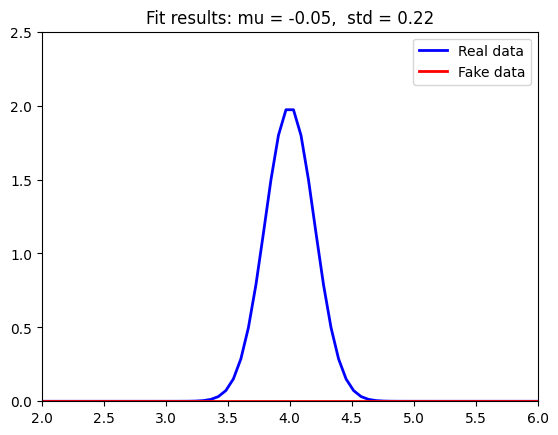

Epoch=0, Discriminator loss=0.6541663706302643, Generator loss=1.2529360055923462


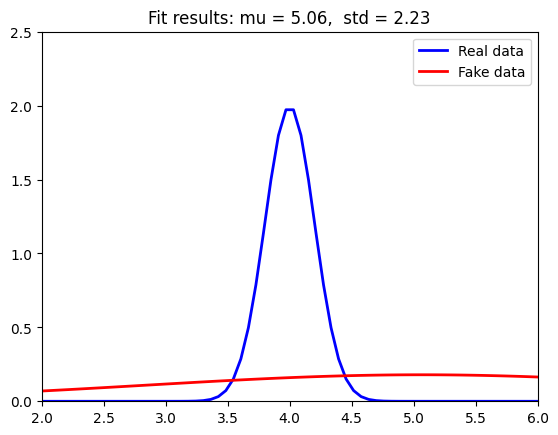

Epoch=1, Discriminator loss=1.2310837507247925, Generator loss=0.560460090637207


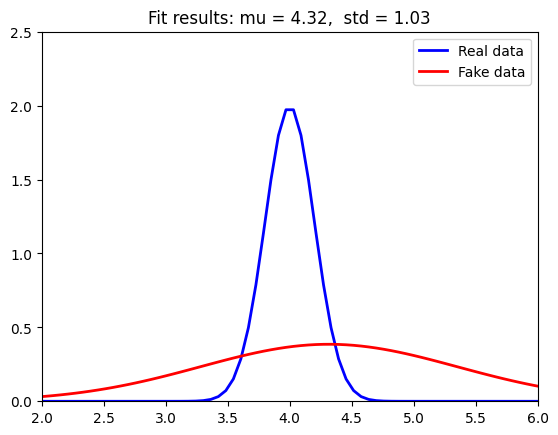

Epoch=2, Discriminator loss=0.5453584492206573, Generator loss=0.8969751000404358


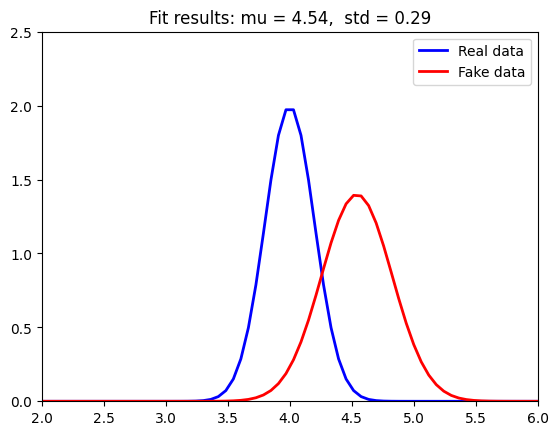

Epoch=3, Discriminator loss=0.44964994490146637, Generator loss=1.3271088600158691


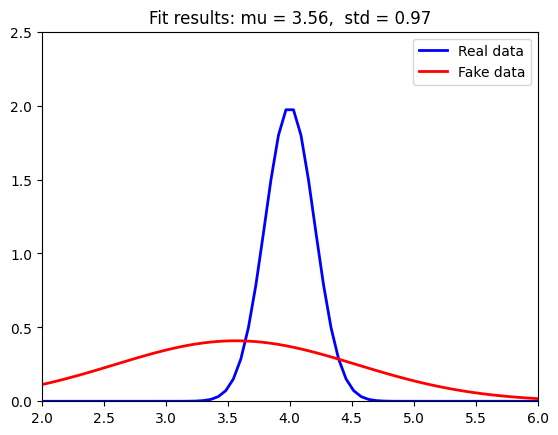

Epoch=4, Discriminator loss=0.8239181637763977, Generator loss=0.732714056968689


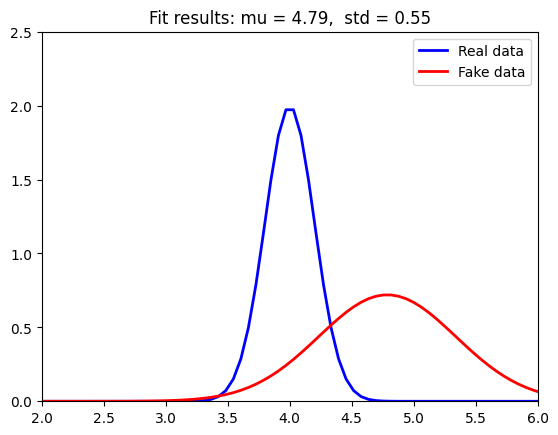

Epoch=5, Discriminator loss=0.7619515657424927, Generator loss=0.8676586151123047


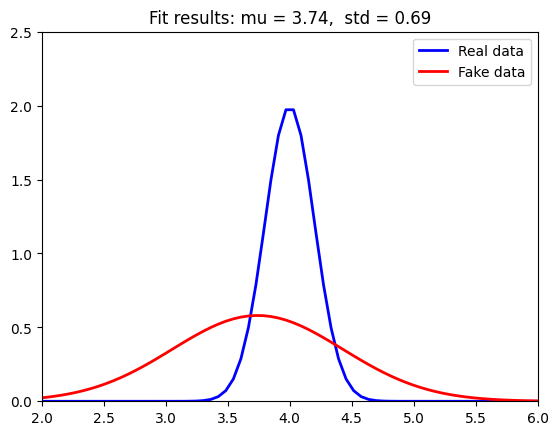

Epoch=6, Discriminator loss=0.6919150948524475, Generator loss=1.1806460618972778


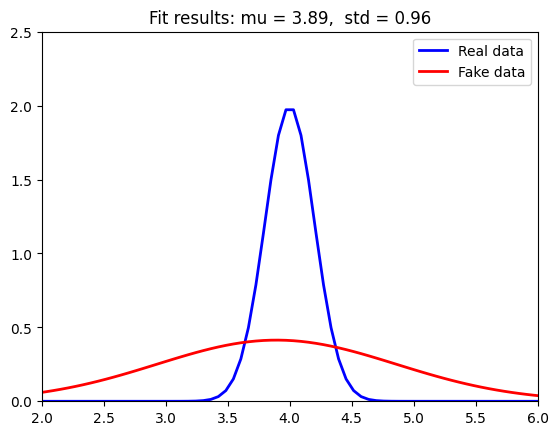

Epoch=7, Discriminator loss=0.4594973474740982, Generator loss=1.2431508302688599


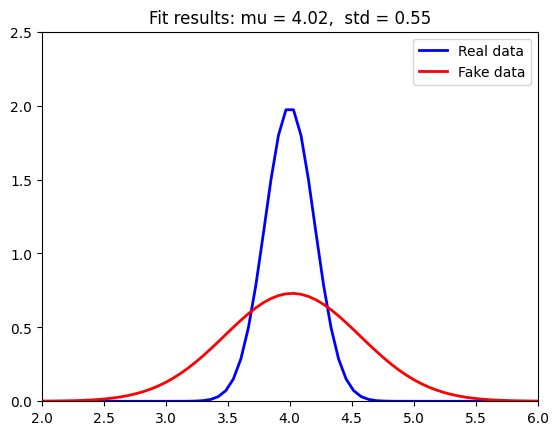

Epoch=8, Discriminator loss=0.8989247679710388, Generator loss=0.6194465756416321


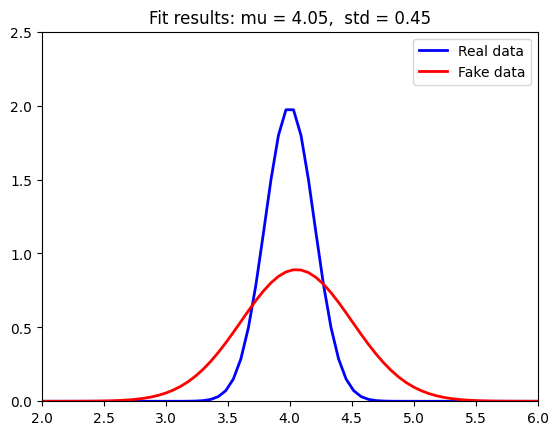

Epoch=9, Discriminator loss=0.5273128002882004, Generator loss=1.3305503129959106


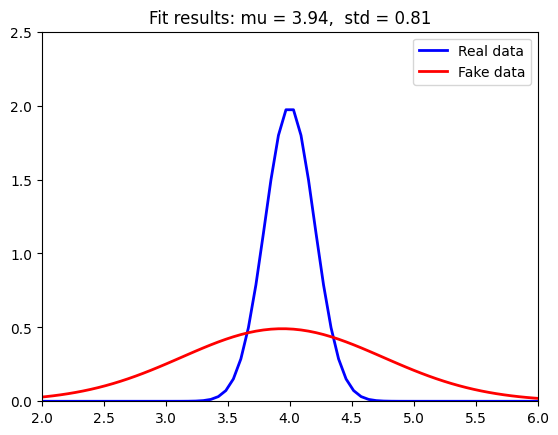

Epoch=10, Discriminator loss=1.1170309484004974, Generator loss=0.35556045174598694


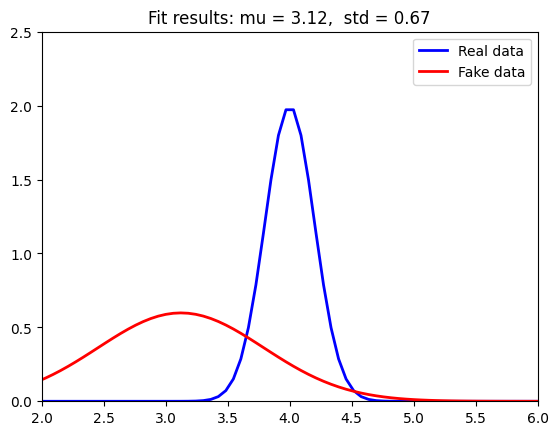

Epoch=11, Discriminator loss=1.1693071722984314, Generator loss=0.38710135221481323


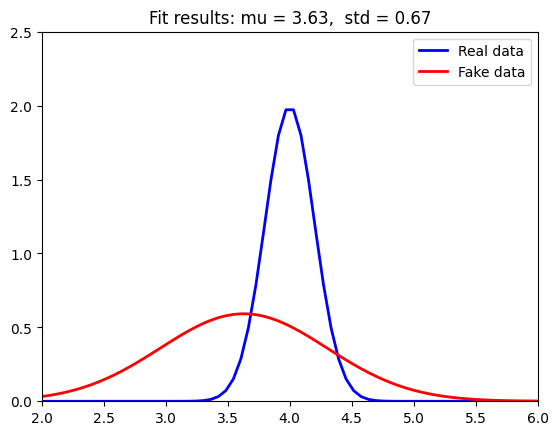

Epoch=12, Discriminator loss=0.6243251264095306, Generator loss=0.8557730317115784


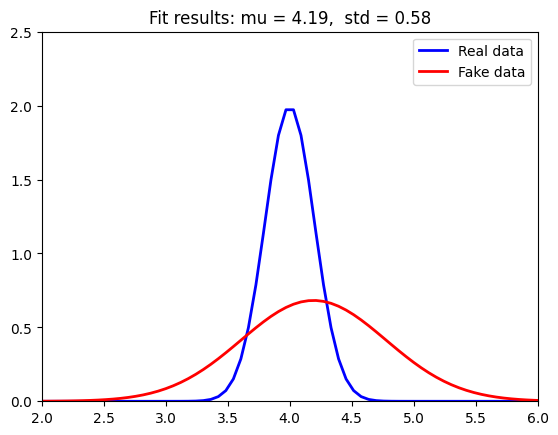

Epoch=13, Discriminator loss=0.6869259774684906, Generator loss=0.7623260617256165


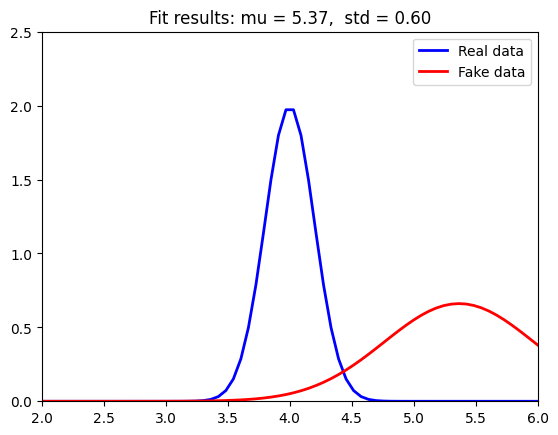

Epoch=14, Discriminator loss=0.5090451836585999, Generator loss=1.0408397912979126


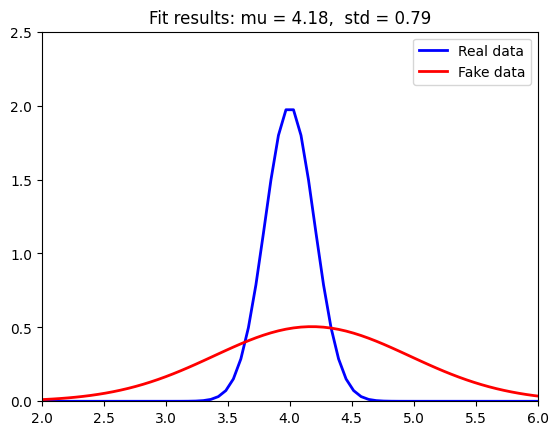

Epoch=15, Discriminator loss=0.5468301028013229, Generator loss=1.4670807123184204


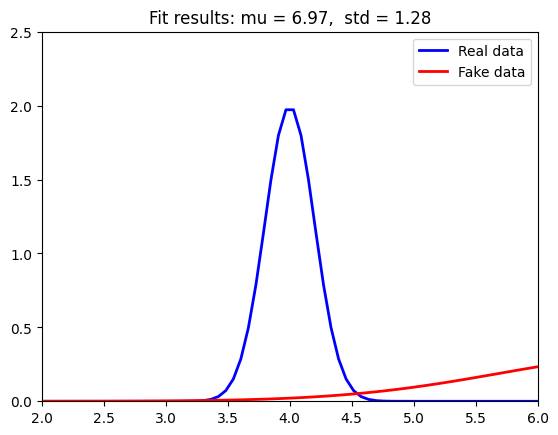

Epoch=16, Discriminator loss=0.7712770104408264, Generator loss=0.6982784271240234


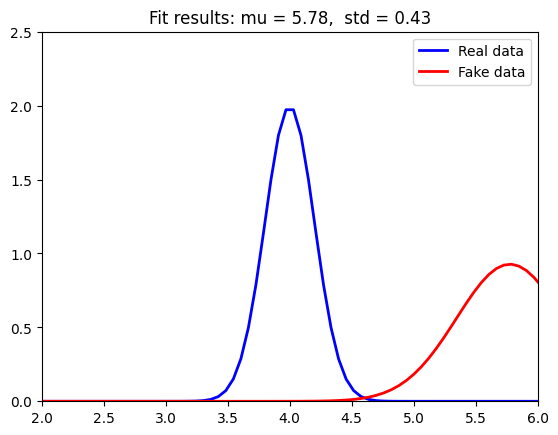

Epoch=17, Discriminator loss=0.5078688263893127, Generator loss=1.0625025033950806


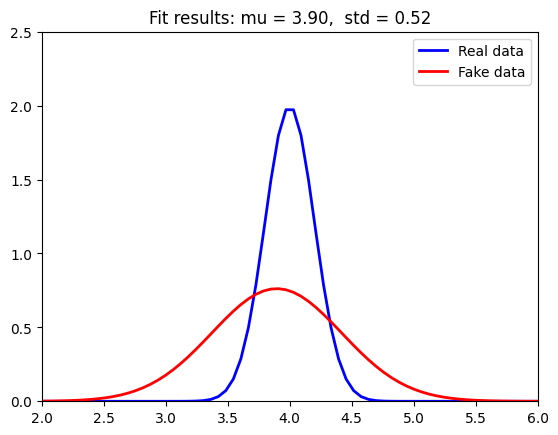

Epoch=18, Discriminator loss=0.7942624986171722, Generator loss=0.7050897479057312


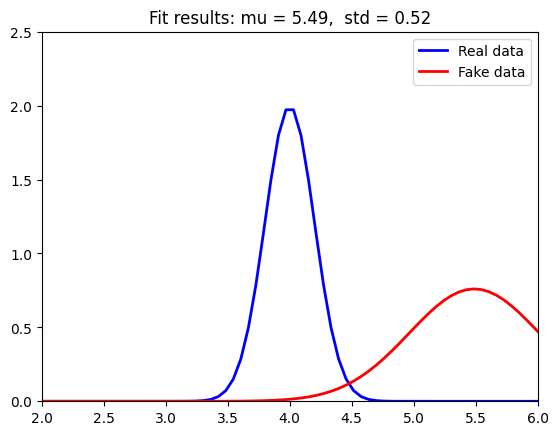

Epoch=19, Discriminator loss=0.5014650076627731, Generator loss=1.6943548917770386


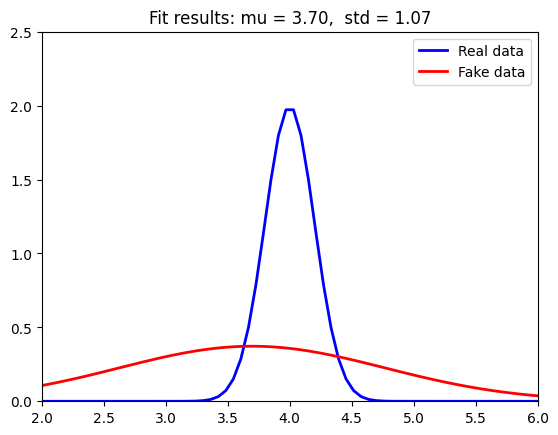

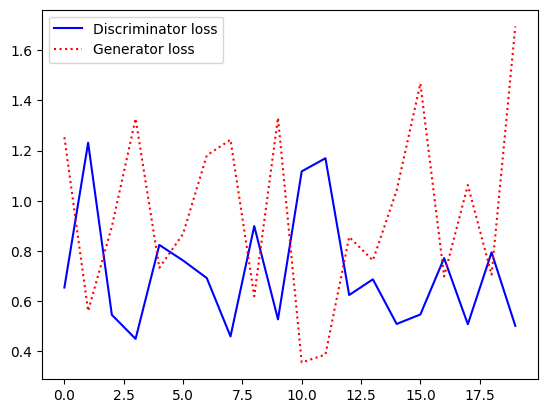

In [ ]:
def main():
    vector_length = 10  # Defines the length of the vector that defines a data sample

    generator_input_size = 50  # Input size of the generator (latent space)
    generator_hidden_size = 150
    generator_output_size = vector_length

    discriminator_input_size = vector_length
    discriminator_hidden_size = 75
    discriminator_output_size = 1

    batch_size = 30
    number_of_batches = 600

    # Creating the GAN generator
    generator = Generator(input_size=generator_input_size, hidden_size=generator_hidden_size,
                          output_size=generator_output_size).to(device)
    generator_learning_rate = 0.001
    generator_loss = nn.BCELoss()
    generator_optimizer = optim.SGD(generator.parameters(), lr=generator_learning_rate, momentum=0.9)

    # Creating the GAN discriminator
    discriminator = Discriminator(input_size=discriminator_input_size, hidden_size=discriminator_hidden_size,
                                  output_size=discriminator_output_size).to(device)

    discriminator_learning_rate = 0.001
    discriminator_loss = nn.BCELoss()
    discriminator_optimizer = optim.SGD(discriminator.parameters(), lr=discriminator_learning_rate, momentum=0.9)

    epochs = 20 # Training epochs
    freeze_generator_steps = 1

    noise_for_plot = read_latent_space(batch_size, generator_input_size)
    discriminator_loss_storage, generator_loss_storage = [], []

    print('Real dataset loaded...')
    print('Starting adversarial GAN training for {} epochs.'.format(epochs))

    # Plot a little bit of trash
    generator_output = generator(noise_for_plot)
    plot_data(real_data_mean, real_data_stddev, generator_output, -1)

    for epoch in range(epochs):

        batch_number = 0

        # training discriminator
        while batch_number < number_of_batches:

            # 1. Train the discriminator
            discriminator.zero_grad()
            # 1.1 Train discriminator on real data
            input_real = get_real_data(batch_size, discriminator_input_size)
            discriminator_real_out = discriminator(input_real)
            discriminator_real_loss = discriminator_loss(discriminator_real_out, real_data_target(batch_size))
            discriminator_real_loss.backward()
            # 1.2 Train the discriminator on data produced by the generator
            input_fake = read_latent_space(batch_size, generator_input_size)
            generator_fake_out = generator(input_fake).detach() # Synthetic data
            discriminator_fake_out = discriminator(generator_fake_out)
            discriminator_fake_loss = discriminator_loss(discriminator_fake_out, fake_data_target(batch_size))
            discriminator_fake_loss.backward()
            # 1.3 Optimizing the discriminator weights
            discriminator_optimizer.step()

            # discriminator_total_loss = discriminator_real_loss + discriminator_fake_loss
            # discriminator_total_loss.backward()
            # discriminator_optimizer.step()


            # 2. Train the generator
            if batch_number % freeze_generator_steps == 0:
              generator.zero_grad()
              # 2.1 Create fake data
              input_fake = read_latent_space(batch_size, generator_input_size)
              generator_fake_out = generator(input_fake)
              # 2.2 Try to fool the discriminator with fake data
              discriminator_out_to_train_generator = discriminator(generator_fake_out)
              discriminator_loss_to_train_generator = generator_loss(discriminator_out_to_train_generator,
                                                                    real_data_target(batch_size))
              discriminator_loss_to_train_generator.backward()
              # 2.3 Optimizing the generator weights
              generator_optimizer.step()

            batch_number += 1

        discriminator_loss_storage.append((discriminator_fake_loss.item() + discriminator_real_loss.item())/2)
        generator_loss_storage.append(discriminator_loss_to_train_generator.item())
        print('Epoch={}, Discriminator loss={}, Generator loss={}'.format(epoch, discriminator_loss_storage[-1],
                                                                          generator_loss_storage[-1]))

        if epoch % 1 == 0:
            generator_output = generator(noise_for_plot)
            plot_data(real_data_mean, real_data_stddev, generator_output, epoch)


    plot_loss_evolution(discriminator_loss_storage, generator_loss_storage)

main()